# Three-agent rubric grading: Qwen3.5 9B

This notebook extends the rubric grading in `Run_Base_Models_v2_rubrics.ipynb` (which is left unchanged) into a three-agent pipeline. All three agents use the same 4-bit NF4 `Qwen/Qwen3.5-9B` model in non-thinking mode. `training_data.csv` is split 80/10/10 by question with seeds 42, 123 and 2026, and the pipeline is evaluated on each seed's test split.

1. **Grading agent**: the original rubric grader. It returns one binary mark per criterion with the same prompt, greedy decoding and parser.
2. **Feedback agent**: writes feedback for the grading agent's criterion marks and score.
3. **Evaluation agent**: grades the answer again, exactly like the grading agent. If its criterion array differs from the grader's, it grades a third time, and the final mark for each criterion is the most common of the three. If the final grade differs from the grader's, the feedback agent runs again for the final grade.

The final grades are scored with the original `calculate_metrics` pipeline, per seed and as the mean ± std across seeds. Grader-only metrics come from the same run, so the two can be compared without extra generation.

> With `EVALUATOR_DO_SAMPLE = False` the evaluation agent decodes greedily, just like the grader, so it will almost always agree. The final grades will then match the single grader. The agreement rate is reported in Section 11.

## 1. Install inference and analysis dependencies

Recent Transformers support is required for Qwen3.8, Gemma 4, Granite 4.2, and Ornith 1.5. Restart the kernel after this cell if packages are upgraded.


In [2]:
%pip install -U "transformers>=5.16.1" accelerate bitsandbytes kernels torchvision sentencepiece pandas scikit-learn matplotlib tqdm


  Using cached torchvision-0.29.1-cp312-cp312-manylinux_2_28_x86_64.whl.metadata (5.7 kB)
  Using cached cuda_toolkit-13.0.3.0-py2.py3-none-any.whl.metadata (17 kB)
  Using cached nvidia_cudnn_cu13-9.24.0.43-py3-none-manylinux_2_27_x86_64.whl.metadata (1.9 kB)
  Using cached nvidia_cusparselt_cu13-0.8.1-py3-none-manylinux2014_x86_64.whl.metadata (12 kB)
  Using cached nvidia_nccl_cu13-2.30.7-py3-none-manylinux_2_18_x86_64.whl.metadata (2.1 kB)
  Using cached nvidia_nvshmem_cu13-3.4.5-py3-none-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (2.1 kB)
  Using cached nvidia_cublas-13.1.1.3-py3-none-manylinux_2_27_x86_64.whl.metadata (1.8 kB)
  Using cached nvidia_cuda_nvrtc-13.0.88-py3-none-manylinux2010_x86_64.manylinux_2_12_x86_64.whl.metadata (1.7 kB)
  Using cached nvidia_cuda_runtime-13.0.96-py3-none-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (1.7 kB)
  Using cached nvidia_cufft-12.0.0.61-py3-none-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (1.8 kB)
  

## 2. Imports and experiment configuration

The thinking budget is larger because reasoning tokens precede the final JSON array. Greedy decoding keeps comparisons reproducible. Per-model starting batch sizes are tuned for 24 GB of VRAM, and the evaluator automatically retries with a smaller batch after a CUDA out-of-memory error.


In [39]:
import ast
import csv
import gc
import json
import os
import re
import time
from pathlib import Path\


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from tqdm.auto import tqdm
from transformers import (
    AutoModelForCausalLM,
    AutoModelForMultimodalLM,
    AutoProcessor,
    AutoTokenizer,
    BitsAndBytesConfig,
)

if not torch.cuda.is_available():
    raise RuntimeError("A CUDA GPU is required for this benchmark.")

# Load the Hugging Face access token without displaying its secret value.
def read_env_value(path, key):
    if not path.exists():
        raise FileNotFoundError(f"Missing environment file: {path.resolve()}")
    for raw_line in path.read_text(encoding="utf-8").splitlines():
        line = raw_line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        name, value = line.split("=", 1)
        name = name.strip().removeprefix("export ").strip()
        if name != key:
            continue
        value = value.strip()
        if len(value) >= 2 and value[0] == value[-1] and value[0] in ("'", '"'):
            value = value[1:-1]
        return value
    return None



DATASET_PATH = Path("../Datasets/training_data_moh_eng_rubrics.csv")
RESULTS_DIR = Path("./multi_agent_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Increment this tag whenever prompts or generation settings change.
RUN_TAG = "multi_agent_rubrics_nf4_v1"
OVERWRITE_EXISTING = False

# Non-thinking is enabled for the main benchmark. Thinking is retained as
# an opt-in run because its longer generations make the full dataset slow.
THINKING_MODES = [
    False,
    # True,  # Uncomment to add thinking-mode runs.
]
MAX_NEW_TOKENS = {False: 128, True: 1024}

MODEL_SPECS = [
    {"name": "Qwen3.5 9B", "model_id": "Qwen/Qwen3.5-9B", "loader": "multimodal", "batch_size": 8},
]
SPEC = MODEL_SPECS[0]  # All three agents share this one model.

# Question-level 80/10/10 splits; the agents are evaluated on each seed's test split.
TRAINING_SEEDS = [42, 123, 2026]

# Multi-agent settings
FEEDBACK_MAX_NEW_TOKENS = 256
# The evaluation agent grades exactly like the grading agent (greedy decoding).
# Set True to sample instead, which lets the two agents disagree.
EVALUATOR_DO_SAMPLE = False
EVALUATOR_TEMPERATURE = 0.7

compute_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=compute_dtype,
)

print("PyTorch:", torch.__version__)
print("Transformers GPU:", torch.cuda.get_device_name(0))
print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
print("Compute dtype:", compute_dtype)
print("Models:", len(MODEL_SPECS), "| modes per model:", len(THINKING_MODES))

PyTorch: 2.14.1+cu130
Transformers GPU: NVIDIA GeForce RTX 3090
VRAM: 23.6 GB
Compute dtype: torch.bfloat16
Models: 1 | modes per model: 1


## 3. Load and validate the full dataset

This is the same parser used in the archived notebooks. No train/validation/test split is made: every valid CSV row is included in this base-model benchmark.


In [11]:
def parse_array(value):
    """Parse JSON/Python lists and the dataset's quoted [a,b] format."""
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []
    if not isinstance(value, str):
        raise TypeError(f"Expected list-like string, got {type(value)}")

    text = value.strip()
    for _ in range(2):
        try:
            parsed = json.loads(text)
        except json.JSONDecodeError:
            break
        if isinstance(parsed, list):
            return parsed
        if isinstance(parsed, str):
            text = parsed.strip()
            continue
        break

    try:
        parsed = ast.literal_eval(text)
        if isinstance(parsed, list):
            return parsed
        if isinstance(parsed, str):
            text = parsed.strip()
    except (ValueError, SyntaxError):
        pass

    if not (text.startswith("[") and text.endswith("]")):
        raise ValueError(f"Expected a bracketed list, got: {value!r}")
    inner = text[1:-1].strip()
    if not inner:
        return []
    if re.search(r",(?=Answer\s)", inner):
        items = re.split(r",(?=Answer\s)", inner)
    else:
        items = next(csv.reader([inner], skipinitialspace=True))
    return [item.strip() for item in items]


def parse_criteria(value, expected_count):
    """Use the label count to resolve commas embedded in criteria text."""
    items = parse_array(value)
    if len(items) == expected_count:
        return items

    text = value.strip()
    for _ in range(2):
        try:
            decoded = json.loads(text)
        except json.JSONDecodeError:
            break
        if isinstance(decoded, str):
            text = decoded.strip()
        else:
            break

    if text.startswith("[") and text.endswith("]"):
        inner = text[1:-1].strip()
        items = [inner] if expected_count == 1 else re.split(r",(?=Answer\s)", inner)
    items = [item.strip() for item in items]
    if len(items) != expected_count:
        raise ValueError(
            f"Parsed {len(items)} criteria but expected {expected_count}: {value!r}"
        )
    return items


df = pd.read_csv(DATASET_PATH).reset_index(drop=True)
required_columns = [
    "question", "desired_answer", "student_answer",
    "criteria[]", "criteria_score[]", "criteria_max_score[]",
    "student_score",
]
missing = [column for column in required_columns if column not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["criteria_score"] = df["criteria_score[]"].apply(
    lambda value: [int(x) for x in parse_array(value)]
)
df["criteria"] = df.apply(
    lambda row: parse_criteria(row["criteria[]"], len(row["criteria_score"])),
    axis=1,
)
df["criteria_max_score"] = df["criteria_max_score[]"].apply(
    lambda value: [int(x) for x in parse_array(value)]
)
df["student_score"] = pd.to_numeric(df["student_score"], errors="raise")

validation_errors = []
for index, row in df.iterrows():
    lengths = (len(row["criteria"]), len(row["criteria_score"]), len(row["criteria_max_score"]))
    if len(set(lengths)) != 1 or lengths[0] == 0:
        validation_errors.append(f"row {index}: misaligned lengths {lengths}")
    if any(score not in (0, 1) for score in row["criteria_score"]):
        validation_errors.append(f"row {index}: labels must be binary")
    if any(maximum < 0 for maximum in row["criteria_max_score"]):
        validation_errors.append(f"row {index}: maximum scores must be non-negative")
    reconstructed_score = sum(
        score * maximum
        for score, maximum in zip(row["criteria_score"], row["criteria_max_score"])
    )
    if abs(reconstructed_score - float(row["student_score"])) > 1e-9:
        validation_errors.append(
            f"row {index}: student_score does not match weighted criterion labels"
        )

if validation_errors:
    raise ValueError("Dataset validation failed:\n" + "\n".join(validation_errors[:20]))

print("Full dataset rows:", len(df))
print("Total criterion labels:", sum(df["criteria_score"].map(len)))
print("Maximum criteria in one row:", max(df["criteria_score"].map(len)))
display(df[["question", "student_answer", "criteria", "criteria_score", "student_score"]].head())


Full dataset rows: 3778
Total criterion labels: 9294
Maximum criteria in one row: 5


,question,student_answer,criteria,criteria_score,student_score
0,What is the role of a prototype program in pro...,High risk problems are address in the prototyp...,[Answer mentions simulating behaviour of porti...,[0],0
1,What is the role of a prototype program in pro...,To simulate portions of the desired final prod...,[Answer mentions simulating behaviour of porti...,[1],1
2,What is the role of a prototype program in pro...,A prototype program simulates the behaviors of...,[Answer mentions simulating behaviour of porti...,[1],1
3,What is the role of a prototype program in pro...,Defined in the Specification phase a prototype...,[Answer mentions simulating behaviour of porti...,[1],1
4,What is the role of a prototype program in pro...,It is used to let the users have a first idea ...,[Answer mentions simulating behaviour of porti...,[0],0


## 3b. Split by question for each seed

This is the same question-level split as the few-shot notebooks:

- The unique stripped question strings are shuffled with each seed in `TRAINING_SEEDS` (42, 123, 2026).
- Questions are assigned 80% to train, 10% to validation and the rest to test; row proportions may differ.
- Every row goes to the split of its question, and the checks reject empty or overlapping splits.

The splits hold `df` row positions. The agents are evaluated only on each seed's **test** split; this notebook does no training.

In [12]:
import random
from collections import defaultdict

question_keys = [str(question).strip() for question in df["question"]]
unique_questions = list(dict.fromkeys(question_keys))


def make_question_splits(split_seed):
    shuffled_questions = unique_questions.copy()
    random.Random(split_seed).shuffle(shuffled_questions)
    n_questions = len(shuffled_questions)
    train_end = int(n_questions * 0.80)
    validation_end = train_end + int(n_questions * 0.10)
    question_splits = {
        "train": shuffled_questions[:train_end],
        "validation": shuffled_questions[train_end:validation_end],
        "test": shuffled_questions[validation_end:],
    }
    if any(not questions for questions in question_splits.values()):
        raise ValueError("Too few unique questions for nonempty 80/10/10 splits.")
    assert sum(map(len, question_splits.values())) == len(set.union(
        *(set(questions) for questions in question_splits.values())
    )) == n_questions
    indices_by_question = defaultdict(list)
    for index, question in enumerate(question_keys):
        indices_by_question[question].append(index)
    # Preserve the seeded question order in training, validation, and test.
    splits = {
        name: [index for question in questions for index in indices_by_question[question]]
        for name, questions in question_splits.items()
    }
    assert sum(map(len, splits.values())) == len(df)
    return {"split_seed": split_seed, "question_splits": question_splits, "splits": splits}


seed_data = {seed: make_question_splits(seed) for seed in TRAINING_SEEDS}
for seed, data in seed_data.items():
    print(f"Seed {seed} question split:")
    for name, split in data["splits"].items():
        print(f"  {name}: {len(split)} rows / {len(data['question_splits'][name])} questions")

# The agents run once on every row that is in any seed's test split. Each seed is then
# scored on its own test rows, so rows shared between seeds are not regenerated.
TEST_INDICES = sorted(set().union(*(data["splits"]["test"] for data in seed_data.values())))
print("Rows in at least one test split:", len(TEST_INDICES), "of", len(df))

Seed 42 question split:
  train: 2980 rows / 76 questions
  validation: 409 rows / 9 questions
  test: 389 rows / 10 questions
Seed 123 question split:
  train: 2889 rows / 76 questions
  validation: 611 rows / 9 questions
  test: 278 rows / 10 questions
Seed 2026 question split:
  train: 3113 rows / 76 questions
  validation: 269 rows / 9 questions
  test: 396 rows / 10 questions
Rows in at least one test split: 950 of 3778


## 4. Shared grading prompt and strict output parser

The final answer must be one ordered binary JSON array. In thinking mode, reasoning may appear before the answer; the parser selects the last binary array with the required length.


In [13]:
SYSTEM_PROMPT = (
    "You are a strict grading assistant.\n\n"
    "Your task is to evaluate whether a student's answer fulfills each grading criterion.\n\n"
    "For each criterion:\n"
    "- Output 1 if the criterion is fulfilled.\n"
    "- Output 0 if the criterion is not fulfilled.\n\n"
    "Evaluate each criterion independently.\n\n"
    "Return ONLY a valid JSON array containing 0 or 1.\n"
    "The output array must contain exactly one value for each criterion, "
    "in the same order as the criteria provided.\n\n"
    "Do not include explanations in the final answer.\n"
    "Do not include markdown in the final answer.\n"
    "Do not include any text after the final JSON array."
)


def build_messages(row):
    criteria_text = "\n".join(
        f"{index + 1}. {criterion}"
        for index, criterion in enumerate(row["criteria"])
    )
    user_prompt = (
        f"Question:\n{row['question']}\n\n"
        f"Desired answer:\n{row['desired_answer']}\n\n"
        f"Student answer:\n{row['student_answer']}\n\n"
        f"Criteria:\n{criteria_text}"
    )
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_prompt},
    ]


def parse_prediction(raw_output, expected_count):
    """Return a valid binary array, tolerating a preceding thinking trace."""
    text = raw_output.strip()
    final_segment = text.rsplit("</think>", 1)[-1].strip()

    candidates = []
    for candidate_text in (final_segment, text):
        try:
            parsed = json.loads(candidate_text)
            candidates.append(parsed)
        except json.JSONDecodeError:
            pass

    for match in re.findall(r"\[\s*[01](?:\s*,\s*[01])*\s*\]", text):
        candidates.append(json.loads(match))

    for candidate in reversed(candidates):
        if not isinstance(candidate, list):
            continue
        try:
            scores = [int(value) for value in candidate]
        except (TypeError, ValueError):
            continue
        if len(scores) == expected_count and all(value in (0, 1) for value in scores):
            return {"valid": True, "scores": scores, "error": None}

    return {
        "valid": False,
        "scores": None,
        "error": f"No binary JSON array of length {expected_count} was found.",
    }

print(SYSTEM_PROMPT)


You are a strict grading assistant.

Your task is to evaluate whether a student's answer fulfills each grading criterion.

For each criterion:
- Output 1 if the criterion is fulfilled.
- Output 0 if the criterion is not fulfilled.

Evaluate each criterion independently.

Return ONLY a valid JSON array containing 0 or 1.
The output array must contain exactly one value for each criterion, in the same order as the criteria provided.

Do not include explanations in the final answer.
Do not include markdown in the final answer.
Do not include any text after the final JSON array.


## 5. Model loading, thinking control, and VRAM cleanup

Multimodal model classes are used for Qwen, Gemma, and Ornith; Granite uses its causal-language-model class. Only text is supplied. The prompt is checked to ensure that each model's chat template actually changes when thinking is toggled.


In [15]:
def clear_cuda_cache():
    gc.collect()
    torch.cuda.empty_cache()
    if hasattr(torch.cuda, "ipc_collect"):
        torch.cuda.ipc_collect()


def print_vram(prefix):
    allocated = torch.cuda.memory_allocated() / 1024**3
    reserved = torch.cuda.memory_reserved() / 1024**3
    print(f"{prefix}: allocated={allocated:.2f} GiB, reserved={reserved:.2f} GiB")


def load_processor(model_id):
    try:
        processor = AutoProcessor.from_pretrained(
            model_id, trust_remote_code=True
        )
    except (ValueError, OSError):
        processor = AutoTokenizer.from_pretrained(
            model_id, trust_remote_code=True
        )
    tokenizer = getattr(processor, "tokenizer", processor)
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "left"
    return processor, tokenizer


def load_model(spec):
    print(f"Loading {spec['name']} from {spec['model_id']}")
    processor, tokenizer = load_processor(spec["model_id"])
    model_class = (
        AutoModelForMultimodalLM
        if spec["loader"] == "multimodal"
        else AutoModelForCausalLM
    )
    model = model_class.from_pretrained(
        spec["model_id"],
        quantization_config=bnb_config,
        dtype=compute_dtype,
        device_map="auto",
        low_cpu_mem_usage=True,
        trust_remote_code=True,
        
    )
    model.eval()
    if hasattr(model.config, "use_cache"):
        model.config.use_cache = True
    print_vram(f"After loading {spec['name']}")
    return model, processor, tokenizer


def render_prompt(processor, messages, thinking):
    return processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=thinking,
    )


def verify_thinking_toggle(processor):
    sample_messages = build_messages(df.iloc[0])
    direct_prompt = render_prompt(processor, sample_messages, thinking=False)
    thinking_prompt = render_prompt(processor, sample_messages, thinking=True)
    if direct_prompt == thinking_prompt:
        raise RuntimeError(
            "This model's chat template ignored enable_thinking; the two runs "
            "would not be a valid thinking/non-thinking comparison."
        )
    print("Thinking toggle verified in the chat template.")


## 6. Resumable inference and metric calculation

Each model/mode pair writes one JSONL file under `base_model_results`. If execution is interrupted, rerunning the benchmark skips completed dataset indices. Invalid outputs count as failures for response-level and final-score accuracies, matching the archived evaluation. Criterion-level metrics and MAE/RMSE use structurally valid predictions, also matching the archived code.


In [17]:
from sklearn.metrics import cohen_kappa_score

METRIC_COLUMNS = [
    "invalid_output_rate",
    "exact_match_accuracy",
    "per_criterion_accuracy",
    "precision",
    "recall",
    "f1",
    "final_score_exact_accuracy",
    "final_score_within_one_accuracy",
    "final_score_mae",
    "final_score_rmse",
    "final_score_pearson",
    "final_score_qwk",
]


def mode_name(thinking):
    return "thinking" if thinking else "non-thinking"


def run_slug(spec, thinking):
    name = re.sub(r"[^a-z0-9]+", "_", spec["name"].lower()).strip("_")
    return f"{RUN_TAG}__{name}__{mode_name(thinking)}"


def prediction_path(spec, thinking):
    return RESULTS_DIR / f"{run_slug(spec, thinking)}.jsonl"


def load_prediction_records(path):
    if not path.exists():
        return []
    records = []
    with path.open("r", encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            if not line.strip():
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError:
                print(f"Ignoring incomplete JSONL line {line_number} in {path.name}")
    # If an interrupted retry produced a duplicate, retain the latest record.
    by_index = {int(record["dataset_index"]): record for record in records}
    return [by_index[index] for index in sorted(by_index)]


def append_prediction_records(path, records):
    with path.open("a", encoding="utf-8") as handle:
        for record in records:
            handle.write(json.dumps(record, ensure_ascii=False) + "\n")


def input_device_for(model):
    try:
        return model.get_input_embeddings().weight.device
    except (AttributeError, NotImplementedError):
        return next(model.parameters()).device


def generate_batch(model, processor, tokenizer, rows, thinking):
    prompts = [
        render_prompt(processor, build_messages(row), thinking=thinking)
        for row in rows
    ]
    inputs = tokenizer(
        prompts,
        return_tensors="pt",
        padding=True,
        add_special_tokens=False,
    )
    input_width = inputs["input_ids"].shape[1]
    device = input_device_for(model)
    inputs = {key: value.to(device) for key, value in inputs.items()}

    started = time.perf_counter()
    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS[thinking],
            do_sample=False,
            use_cache=True,
            pad_token_id=tokenizer.pad_token_id,
        )
    elapsed = time.perf_counter() - started
    continuation_ids = generated[:, input_width:].detach().cpu()
    outputs = tokenizer.batch_decode(continuation_ids, skip_special_tokens=True)

    del inputs, generated, continuation_ids
    return [output.strip() for output in outputs], elapsed


def calculate_metrics(records, spec, thinking, expected_count=None):
    # expected_count lets the same metrics score one seed's test split.
    expected_count = len(df) if expected_count is None else expected_count
    if len(records) != expected_count:
        raise ValueError(f"Expected {expected_count} records but found {len(records)}.")

    criterion_true = []
    criterion_pred = []
    exact_correct = 0
    invalid_count = 0
    final_score_errors = []
    final_score_exact = 0
    final_score_within_one = 0

    y_true_scores = []
    y_pred_scores = []

    for record in records:
        true_scores = record["ground_truth"]
        pred_scores = record["prediction"] if record["valid"] else None
        exact_correct += int(record["valid" ] and pred_scores == true_scores)
        invalid_count += int(not record["valid"])

        if record["valid"]:
            criterion_true.extend(true_scores)
            criterion_pred.extend(pred_scores)
            error = abs(record["predicted_final_score"] - record["true_final_score"])
            final_score_errors.append(error)
            final_score_exact += int(error == 0)
            final_score_within_one += int(error <= 1)

            y_true_scores.append(record["true_final_score"])
            y_pred_scores.append(record["predicted_final_score"])

    total = len(records)
    elapsed_seconds = sum(float(record.get("generation_seconds", 0.0)) for record in records)

    # Calculate Pearson Correlation for valid predictions
    pearson_corr = float("nan")
    if len(y_true_scores) > 1:
        corr_matrix = np.corrcoef(y_true_scores, y_pred_scores)
        if not np.isnan(corr_matrix[0, 1]):
            pearson_corr = float(corr_matrix[0, 1])

    # Calculate Quadratic Weighted Kappa for valid predictions
    qwk = float("nan")
    if len(y_true_scores) > 0:
        try:
            # Round predictions to nearest integers for discrete kappa categories
            y_pred_rounded = [int(round(s)) for s in y_pred_scores]
            y_true_rounded = [int(round(s)) for s in y_true_scores]
            qwk = float(cohen_kappa_score(y_true_rounded, y_pred_rounded, weights="quadratic"))
        except Exception:
            pass

    return {
        "model": spec["name"],
        "model_id": spec["model_id"],
        "mode": mode_name(thinking),
        "examples": total,
        "invalid_output_rate": invalid_count / total if total else 0.0,
        "exact_match_accuracy": exact_correct / total if total else 0.0,
        "per_criterion_accuracy": accuracy_score(criterion_true, criterion_pred) if criterion_true else 0.0,
        "precision": precision_score(criterion_true, criterion_pred, zero_division=0) if criterion_true else 0.0,
        "recall": recall_score(criterion_true, criterion_pred, zero_division=0) if criterion_true else 0.0,
        "f1": f1_score(criterion_true, criterion_pred, zero_division=0) if criterion_true else 0.0,
        "final_score_exact_accuracy": final_score_exact / total if total else 0.0,
        "final_score_within_one_accuracy": final_score_within_one / total if total else 0.0,
        "final_score_mae": float(np.mean(final_score_errors)) if final_score_errors else float("nan"),
        "final_score_rmse": float(np.sqrt(np.mean(np.square(final_score_errors)))) if final_score_errors else float("nan"),
        "final_score_pearson": pearson_corr,
        "final_score_qwk": qwk,
        "generation_minutes": elapsed_seconds / 60,
        "mean_generation_seconds": elapsed_seconds / total if total else float("nan"),
    }


def evaluate_model_mode(model, processor, tokenizer, spec, thinking):
    path = prediction_path(spec, thinking)
    if OVERWRITE_EXISTING and path.exists():
        path.unlink()

    existing = load_prediction_records(path)
    completed = {int(record["dataset_index"]) for record in existing}
    pending = [index for index in range(len(df)) if index not in completed]
    active_batch_size = spec["batch_size"]

    print(
        f"{spec['name']} | {mode_name(thinking)}: "
        f"{len(completed)} complete, {len(pending)} remaining"
    )

    position = 0
    with tqdm(total=len(pending), desc=f"{spec['name']} | {mode_name(thinking)}") as progress:
        while position < len(pending):
            batch_indices = pending[position:position + active_batch_size]
            rows = [df.iloc[index] for index in batch_indices]
            try:
                raw_outputs, elapsed = generate_batch(
                    model, processor, tokenizer, rows, thinking
                )
            except torch.OutOfMemoryError:
                clear_cuda_cache()
                if active_batch_size == 1:
                    raise
                active_batch_size = max(1, active_batch_size // 2)
                print(f"CUDA OOM: retrying with batch size {active_batch_size}")
                continue

            batch_records = []
            seconds_per_example = elapsed / len(batch_indices)
            for dataset_index, row, raw_output in zip(batch_indices, rows, raw_outputs):
                parsed = parse_prediction(raw_output, len(row["criteria_score"]))
                pred_scores = parsed["scores"]
                predicted_final_score = (
                    sum(score * maximum for score, maximum in zip(pred_scores, row["criteria_max_score"]))
                    if parsed["valid"] else None
                )
                batch_records.append({
                    "dataset_index": int(dataset_index),
                    "dataset_id": str(row["id"]) if "id" in row else str(dataset_index),
                    "model": spec["name"],
                    "model_id": spec["model_id"],
                    "mode": mode_name(thinking),
                    "valid": parsed["valid"],
                    "error": parsed["error"],
                    "ground_truth": [int(value) for value in row["criteria_score"]],
                    "prediction": pred_scores,
                    "criteria_max_score": [int(value) for value in row["criteria_max_score"]],
                    "true_final_score": float(row["student_score"]),
                    "predicted_final_score": predicted_final_score,
                    "raw_output": raw_output,
                    "generation_seconds": seconds_per_example,
                })

            append_prediction_records(path, batch_records)
            position += len(batch_indices)
            progress.update(len(batch_indices))

    records = load_prediction_records(path)
    return calculate_metrics(records, spec, thinking), records

## 7. The agents

- `generate_messages_batch` uses the same left-padded batching as `generate_batch`, but accepts any chat messages, so the feedback agent can use it.
- The feedback agent sees each criterion marked `met` or `not met`, plus the final score. It returns `{"feedback": "..."}`. If the output can't be parsed, the raw text is kept and flagged with `feedback_valid = False`.
- `resolve_grades` takes the most common mark for each criterion. With three binary votes a majority always exists, so no tie-break is needed.

In [18]:
def generate_messages_batch(model, processor, tokenizer, message_lists, max_new_tokens,
                            do_sample=False, temperature=None):
    """Same batching and decoding as generate_batch, for arbitrary chat messages."""
    prompts = [render_prompt(processor, messages, thinking=False) for messages in message_lists]
    inputs = tokenizer(
        prompts,
        return_tensors="pt",
        padding=True,
        add_special_tokens=False,
    )
    input_width = inputs["input_ids"].shape[1]
    device = input_device_for(model)
    inputs = {key: value.to(device) for key, value in inputs.items()}
    sampling = {"do_sample": True, "temperature": temperature} if do_sample else {"do_sample": False}

    started = time.perf_counter()
    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            use_cache=True,
            pad_token_id=tokenizer.pad_token_id,
            **sampling,
        )
    elapsed = time.perf_counter() - started
    continuation_ids = generated[:, input_width:].detach().cpu()
    outputs = tokenizer.batch_decode(continuation_ids, skip_special_tokens=True)

    del inputs, generated, continuation_ids
    return [output.strip() for output in outputs], elapsed

In [30]:
FEEDBACK_SYSTEM_PROMPT = (
    "You are a supportive teaching assistant giving feedback on a student's exam answer.\n\n"
    "The answer has already been graded against each criterion. "
    "The marks are final: do not change, question, or re-grade them.\n\n"
    "Write 1-2 sentences of constructive feedback addressed to the student that:\n"
    "- explains why the answer received its score,\n"
    "- acknowledges what the answer did well (criteria marked met),\n"
    "- explains what was missing or incorrect for each criterion marked not met, "
    "and how to improve it.\n\n"
    "Return ONLY a valid JSON object of the form {\"feedback\": \"<text>\"}.\n"
    "Do not include markdown or any text outside the JSON object."
)


def weighted_score(criterion_scores, criterion_maximums):
    return sum(score * maximum for score, maximum in zip(criterion_scores, criterion_maximums))


def build_feedback_messages(row, criterion_scores):
    criteria_text = "\n".join(
        f"{index + 1}. [{'met' if score else 'not met'}] {criterion}"
        for index, (criterion, score) in enumerate(zip(row["criteria"], criterion_scores))
    )
    final_score = weighted_score(criterion_scores, row["criteria_max_score"])
    max_score = sum(row["criteria_max_score"])
    user_prompt = (
        f"Question:\n{row['question']}\n\n"
        f"Desired answer:\n{row['desired_answer']}\n\n"
        f"Student answer:\n{row['student_answer']}\n\n"
        f"Graded criteria:\n{criteria_text}\n\n"
        f"Final score: {final_score} / {max_score}"
    )
    return [
        {"role": "system", "content": FEEDBACK_SYSTEM_PROMPT},
        {"role": "user", "content": user_prompt},
    ]


def parse_feedback(raw_output):
    """Always return plain-text feedback, whether the model wrote valid JSON, broken JSON, or plain text."""
    text = raw_output.strip().rsplit("</think>", 1)[-1].strip()
    # Drop ```json ... ``` fences if present.
    text = re.sub(r"^```(?:json)?\s*|\s*```$", "", text).strip()

    # 1. Valid JSON (whole text, or the outermost {...}).
    candidates = [text]
    start, end = text.find("{"), text.rfind("}")
    if 0 <= start < end:
        candidates.append(text[start:end + 1])
    for candidate in candidates:
        try:
            parsed = json.loads(candidate)
        except json.JSONDecodeError:
            continue
        if isinstance(parsed, dict) and isinstance(parsed.get("feedback"), str) and parsed["feedback"].strip():
            return {"feedback_valid": True, "feedback": " ".join(parsed["feedback"].split())}

    # 2. Broken JSON wrapper (invalid escapes like \0, unescaped quotes, or cut off at the token limit):
    #    take everything after "feedback": " and strip the closing "} if it is there.
    match = re.search(r'"feedback"\s*:\s*"(.*)', text, flags=re.DOTALL)
    if match:
        feedback = re.sub(r'"?\s*}?\s*$', "", match.group(1))
        feedback = feedback.replace('\\"', '"').replace("\\n", " ").replace("\\\\", "\\")
        return {"feedback_valid": False, "feedback": " ".join(feedback.split())}

    # 3. Plain text: use as is.
    return {"feedback_valid": False, "feedback": " ".join(text.strip().strip('"').split())}


print(FEEDBACK_SYSTEM_PROMPT)

You are a supportive teaching assistant giving feedback on a student's exam answer.

The answer has already been graded against each criterion. The marks are final: do not change, question, or re-grade them.

Write 1-2 sentences of constructive feedback addressed to the student that:
- explains why the answer received its score,
- acknowledges what the answer did well (criteria marked met),
- explains what was missing or incorrect for each criterion marked not met, and how to improve it.

Return ONLY a valid JSON object of the form {"feedback": "<text>"}.
Do not include markdown or any text outside the JSON object.


In [20]:
def resolve_grades(grader, evaluator, regrade=None):
    """Combine parse_prediction results into the final criterion array."""
    if grader["valid"] and evaluator["valid"] and grader["scores"] == evaluator["scores"]:
        return {"valid": True, "scores": grader["scores"], "error": None, "resolution": "agree"}

    valid_arrays = [
        parsed["scores"] for parsed in (grader, evaluator, regrade)
        if parsed is not None and parsed["valid"]
    ]
    if len(valid_arrays) == 3:
        # Most common mark for each criterion; three binary votes always have a majority.
        scores = [int(sum(votes) >= 2) for votes in zip(*valid_arrays)]
        resolution = "majority"
    elif len(valid_arrays) == 2:
        # No majority is possible, so a criterion is met only if both valid grades agree it is.
        scores = [int(all(votes)) for votes in zip(*valid_arrays)]
        resolution = "two_valid"
    elif len(valid_arrays) == 1:
        scores = valid_arrays[0]
        resolution = "single_valid"
    else:
        return {
            "valid": False, "scores": None, "resolution": "invalid",
            "error": "No agent produced a valid criterion array.",
        }
    return {"valid": True, "scores": scores, "error": None, "resolution": resolution}


# Quick self-check of the resolution rules.
_ok = lambda scores: {"valid": True, "scores": scores, "error": None}
_bad = {"valid": False, "scores": None, "error": "invalid"}
assert resolve_grades(_ok([1, 0]), _ok([1, 0]))["resolution"] == "agree"
assert resolve_grades(_ok([1, 0, 1]), _ok([0, 0, 1]), _ok([1, 1, 0]))["scores"] == [1, 0, 1]
assert resolve_grades(_bad, _ok([1, 1]), _ok([1, 0]))["scores"] == [1, 0]
assert resolve_grades(_bad, _bad, _bad)["valid"] is False
print("resolve_grades checks passed.")

resolve_grades checks passed.


## 8. Three-agent orchestrator

For each batch the agents run in this order:

1. **Grading agent:** `generate_batch`, the unchanged grader.
2. **Feedback agent:** writes feedback on the grader's marks.
3. **Evaluation agent:** grades again.
4. **Re-grade:** only for rows where the grader and evaluator arrays differ, or either output is invalid.
5. **Resolve:** the most common mark for each criterion.
6. **Feedback again:** only for rows whose final array differs from the grader's.

Each record keeps the fields that `calculate_metrics` reads. `prediction`, `valid` and `predicted_final_score` are taken from the **final** grade. Records also store every agent's marks, the raw outputs, the resolution and the feedback.

Like the original notebook, results are written to a JSONL file after every batch, and a rerun resumes where it stopped. If a batch runs out of GPU memory, it is retried with half the batch size.

In [31]:
AGENTS = ("grader", "feedback", "evaluator", "regrade", "feedback_regenerated")


def predicted_score(parsed, row):
    return weighted_score(parsed["scores"], row["criteria_max_score"]) if parsed["valid"] else None


def run_evaluation_agent(model, processor, tokenizer, rows):
    if EVALUATOR_DO_SAMPLE:
        return generate_messages_batch(
            model, processor, tokenizer, [build_messages(row) for row in rows],
            MAX_NEW_TOKENS[False], do_sample=True, temperature=EVALUATOR_TEMPERATURE,
        )
    # Identical to the grading agent.
    return generate_batch(model, processor, tokenizer, rows, thinking=False)


def run_feedback_agent(model, processor, tokenizer, rows, criterion_score_lists):
    raw_outputs, elapsed = generate_messages_batch(
        model, processor, tokenizer,
        [build_feedback_messages(row, scores) for row, scores in zip(rows, criterion_score_lists)],
        FEEDBACK_MAX_NEW_TOKENS,
    )
    return [{**parse_feedback(raw), "feedback_raw_output": raw} for raw in raw_outputs], elapsed


def run_agents_on_batch(model, processor, tokenizer, spec, batch_indices, rows):
    n = len(rows)
    seconds = {agent: [0.0] * n for agent in AGENTS}

    def charge(agent, positions, elapsed):
        for position in positions:
            seconds[agent][position] = elapsed / len(positions)

    def parse_all(raw_outputs, positions):
        return [parse_prediction(raw, len(rows[p]["criteria_score"])) for raw, p in zip(raw_outputs, positions)]

    # 1. Grading agent
    grader_raw, elapsed = generate_batch(model, processor, tokenizer, rows, thinking=False)
    charge("grader", range(n), elapsed)
    grader = parse_all(grader_raw, range(n))

    # 2. Feedback agent on the grading agent's marks
    feedback = [None] * n
    graded = [p for p in range(n) if grader[p]["valid"]]
    if graded:
        results, elapsed = run_feedback_agent(
            model, processor, tokenizer,
            [rows[p] for p in graded], [grader[p]["scores"] for p in graded],
        )
        charge("feedback", graded, elapsed)
        for p, result in zip(graded, results):
            feedback[p] = result

    # 3. Evaluation agent
    evaluator_raw, elapsed = run_evaluation_agent(model, processor, tokenizer, rows)
    charge("evaluator", range(n), elapsed)
    evaluator = parse_all(evaluator_raw, range(n))

    # 4. Re-grade rows where the two grades differ (or either is invalid)
    regrade_raw, regrade = [None] * n, [None] * n
    disputed = [
        p for p in range(n)
        if not (grader[p]["valid"] and evaluator[p]["valid"] and grader[p]["scores"] == evaluator[p]["scores"])
    ]
    if disputed:
        raw_outputs, elapsed = run_evaluation_agent(model, processor, tokenizer, [rows[p] for p in disputed])
        charge("regrade", disputed, elapsed)
        for p, raw, parsed in zip(disputed, raw_outputs, parse_all(raw_outputs, disputed)):
            regrade_raw[p], regrade[p] = raw, parsed

    # 5. Most common mark per criterion
    final = [resolve_grades(grader[p], evaluator[p], regrade[p]) for p in range(n)]

    # 6. Regenerate feedback when the final grade differs from the grading agent's
    changed = [p for p in range(n) if final[p]["valid"] and final[p]["scores"] != grader[p]["scores"]]
    if changed:
        results, elapsed = run_feedback_agent(
            model, processor, tokenizer,
            [rows[p] for p in changed], [final[p]["scores"] for p in changed],
        )
        charge("feedback_regenerated", changed, elapsed)
        for p, result in zip(changed, results):
            feedback[p] = result

    records = []
    for p, (dataset_index, row) in enumerate(zip(batch_indices, rows)):
        agent_seconds = {agent: seconds[agent][p] for agent in AGENTS}
        records.append({
            # Fields read by calculate_metrics (final three-agent grade)
            "dataset_index": int(dataset_index),
            "dataset_id": str(row["id"]) if "id" in row else str(dataset_index),
            "model": spec["name"],
            "model_id": spec["model_id"],
            "mode": mode_name(False),
            "valid": final[p]["valid"],
            "error": final[p]["error"],
            "ground_truth": [int(value) for value in row["criteria_score"]],
            "prediction": final[p]["scores"],
            "criteria_max_score": [int(value) for value in row["criteria_max_score"]],
            "true_final_score": float(row["student_score"]),
            "predicted_final_score": predicted_score(final[p], row),
            "raw_output": grader_raw[p],
            "generation_seconds": sum(agent_seconds.values()),
            # Per-agent detail
            "grader_valid": grader[p]["valid"],
            "grader_error": grader[p]["error"],
            "grader_prediction": grader[p]["scores"],
            "grader_final_score": predicted_score(grader[p], row),
            "evaluator_valid": evaluator[p]["valid"],
            "evaluator_prediction": evaluator[p]["scores"],
            "evaluator_raw_output": evaluator_raw[p],
            "regraded": p in disputed,
            "regrade_valid": regrade[p]["valid"] if regrade[p] else None,
            "regrade_prediction": regrade[p]["scores"] if regrade[p] else None,
            "regrade_raw_output": regrade_raw[p],
            "agents_agreed": final[p]["resolution"] == "agree",
            "resolution": final[p]["resolution"],
            "final_changed": p in changed,
            "feedback": feedback[p]["feedback"] if feedback[p] else None,
            "feedback_valid": feedback[p]["feedback_valid"] if feedback[p] else None,
            "feedback_regenerated": p in changed,
            "feedback_raw_output": feedback[p]["feedback_raw_output"] if feedback[p] else None,
            "agent_seconds": agent_seconds,
        })
    return records


def evaluate_multi_agent(model, processor, tokenizer, spec, path=None, indices=None):
    """Run the three agents over df (or the given indices), resuming from the JSONL file."""
    path = path or prediction_path(spec, False)
    if OVERWRITE_EXISTING and path.exists():
        path.unlink()
    indices = list(range(len(df))) if indices is None else list(indices)

    completed = {int(record["dataset_index"]) for record in load_prediction_records(path)}
    pending = [index for index in indices if index not in completed]
    active_batch_size = spec["batch_size"]
    print(f"{spec['name']} | 3-agent: {len(indices) - len(pending)} complete, {len(pending)} remaining")

    position = 0
    with tqdm(total=len(pending), desc=f"{spec['name']} | 3-agent") as progress:
        while position < len(pending):
            batch_indices = pending[position:position + active_batch_size]
            rows = [df.iloc[index] for index in batch_indices]
            try:
                batch_records = run_agents_on_batch(
                    model, processor, tokenizer, spec, batch_indices, rows
                )
            except torch.OutOfMemoryError:
                clear_cuda_cache()
                if active_batch_size == 1:
                    raise
                active_batch_size = max(1, active_batch_size // 2)
                print(f"CUDA OOM: retrying with batch size {active_batch_size}")
                continue

            append_prediction_records(path, batch_records)
            position += len(batch_indices)
            progress.update(len(batch_indices))

    records_by_index = {int(record["dataset_index"]): record for record in load_prediction_records(path)}
    return [records_by_index[index] for index in indices if index in records_by_index]

## 9. Load the model and run a smoke test

The model is loaded only when the test rows haven't all been graded yet. The smoke test runs the three agents on the first `SMOKE_TEST_ROWS` rows of seed 42's test split and writes them to a separate JSONL file, which is deleted afterwards. It checks that the record shape, the feedback and `calculate_metrics` all work before the long run.

To exercise the disagreement path, set `EVALUATOR_DO_SAMPLE = True` for the smoke test only. Rerun the configuration cell afterwards to reset it.

In [22]:
RUN_PATH = prediction_path(SPEC, False)
graded_indices = {int(record["dataset_index"]) for record in load_prediction_records(RUN_PATH)}
full_run_complete = not OVERWRITE_EXISTING and set(TEST_INDICES) <= graded_indices

model = processor = tokenizer = None
if full_run_complete:
    print(f"Reusing completed run: {RUN_PATH}")
else:
    clear_cuda_cache()
    model, processor, tokenizer = load_model(SPEC)

Loading Qwen3.5 9B from Qwen/Qwen3.5-9B


preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/79.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/760 [00:00<?, ?it/s]

After loading Qwen3.5 9B: allocated=7.35 GiB, reserved=7.40 GiB


In [44]:
RUN_SMOKE_TEST = True
SMOKE_TEST_ROWS = 8

if RUN_SMOKE_TEST and model is not None:
    smoke_path = RESULTS_DIR / f"{RUN_TAG}__smoke_test.jsonl"
    smoke_path.unlink(missing_ok=True)
    smoke_indices = seed_data[TRAINING_SEEDS[0]]["splits"]["test"][:SMOKE_TEST_ROWS]
    smoke_records = evaluate_multi_agent(
        model, processor, tokenizer, SPEC, path=smoke_path, indices=smoke_indices
    )

    for record in smoke_records:
        expected = len(record["ground_truth"])
        assert not record["valid"] or len(record["prediction"]) == expected, record["dataset_index"]
        assert not record["valid"] or (record["feedback"] or "").strip(), record["dataset_index"]
        assert record["regraded"] or record["agents_agreed"] or not record["grader_valid"], record["dataset_index"]
    pd.set_option("display.max_colwidth", None)
    display(pd.DataFrame([
        calculate_metrics(smoke_records, SPEC, False, expected_count=len(smoke_indices))
    ]))

    display(pd.DataFrame(smoke_records)[[
        "dataset_index", "grader_prediction", "evaluator_prediction", "regrade_prediction",
        "prediction", "resolution", "feedback_regenerated", "feedback",
    ]])
    smoke_path.unlink(missing_ok=True)
    print("Smoke test passed.")
else:
    print("Smoke test skipped.")

True
Smoke test skipped.


## 10. Three-agent run on the test splits

This starts or resumes the run over every row that appears in at least one seed's test split (`TEST_INDICES`). Each row is graded once, even when it is in more than one seed's test split. Afterwards the model is deleted and the CUDA cache is cleared.

In [33]:
try:
    if not full_run_complete:
        evaluate_multi_agent(model, processor, tokenizer, SPEC, indices=TEST_INDICES)
finally:
    if model is not None:
        del model
    if processor is not None:
        del processor
    if tokenizer is not None:
        del tokenizer
    model = processor = tokenizer = None
    clear_cuda_cache()
    print_vram(f"After unloading {SPEC['name']}")

records_by_index = {int(record["dataset_index"]): record for record in load_prediction_records(RUN_PATH)}
multi_agent_records = [records_by_index[index] for index in TEST_INDICES if index in records_by_index]
print("Test records:", len(multi_agent_records), "/", len(TEST_INDICES))

Qwen3.5 9B | 3-agent: 0 complete, 950 remaining


Qwen3.5 9B | 3-agent:   0%|          | 0/950 [00:00<?, ?it/s]

After unloading Qwen3.5 9B: allocated=0.01 GiB, reserved=7.23 GiB
Test records: 950 / 950


## 11. Evaluate each seed's test split with the existing pipeline

For each seed in `TRAINING_SEEDS`, `calculate_metrics` from Section 6 scores that seed's test rows. Only its expected record count was made a parameter.

- **3-agent:** the final, resolved grades.
- **Grader only:** the same records with `prediction`, `valid` and `predicted_final_score` swapped for the grading agent's own output.

Results are saved per seed and as the mean ± std across the three seeds. The agent statistics show how often the agents agreed, re-graded, changed the grade and regenerated feedback on each test split.

In [34]:
missing = [index for index in TEST_INDICES if index not in records_by_index]
if missing:
    raise ValueError(f"{len(missing)} test rows are not graded yet; run Section 10 to completion.")


def grader_view(record):
    return {
        **record,
        "valid": record["grader_valid"],
        "error": record["grader_error"],
        "prediction": record["grader_prediction"],
        "predicted_final_score": record["grader_final_score"],
        "generation_seconds": record["agent_seconds"]["grader"],
    }


SYSTEMS = {
    "Qwen3.5 9B (grader only)": grader_view,
    "Qwen3.5 9B (3-agent)": lambda record: record,
}


def agent_statistics(records):
    frame = pd.DataFrame(records)
    with_feedback = frame["feedback_valid"].dropna().astype(bool)
    return {
        "examples": len(frame),
        "grader_valid_rate": frame["grader_valid"].mean(),
        "evaluator_valid_rate": frame["evaluator_valid"].mean(),
        "agreement_rate": frame["agents_agreed"].mean(),
        "regrade_rate": frame["regraded"].mean(),
        "final_changed_rate": frame["final_changed"].mean(),
        "final_score_changed_rate": (
            frame["predicted_final_score"] != frame["grader_final_score"]
        ).mean(),
        "feedback_coverage": frame["feedback"].notna().mean(),
        "feedback_valid_rate": with_feedback.mean() if len(with_feedback) else float("nan"),
        "feedback_regenerated_rate": frame["feedback_regenerated"].mean(),
        **{
            f"resolution_{name}": int((frame["resolution"] == name).sum())
            for name in ("agree", "majority", "two_valid", "single_valid", "invalid")
        },
        "generation_minutes_total": frame["generation_seconds"].sum() / 60,
        **{
            f"generation_minutes_{agent}": frame["agent_seconds"].map(lambda s: s[agent]).sum() / 60
            for agent in AGENTS
        },
    }


metrics_rows, agent_stats_rows = [], []
for seed, data in seed_data.items():
    test_indices = data["splits"]["test"]
    seed_records = [records_by_index[index] for index in test_indices]
    for name, view in SYSTEMS.items():
        metrics = calculate_metrics(
            [view(record) for record in seed_records], {**SPEC, "name": name}, False,
            expected_count=len(test_indices),
        )
        metrics_rows.append({"split_seed": seed, **metrics})
    agent_stats_rows.append({"split_seed": seed, **agent_statistics(seed_records)})

    # Per-seed test records, including every agent's marks and the feedback.
    pd.DataFrame(seed_records).to_csv(
        RESULTS_DIR / f"{RUN_TAG}__test_records_seed{seed}.csv", index=False
    )

metrics_by_seed_df = pd.DataFrame(metrics_rows)
metrics_by_seed_df.to_csv(RESULTS_DIR / f"{RUN_TAG}__metrics_by_seed.csv", index=False)

seed_summary_df = metrics_by_seed_df.groupby("model", sort=False)[METRIC_COLUMNS].agg(["mean", "std"])
seed_summary_df.to_csv(RESULTS_DIR / f"{RUN_TAG}__metrics_seed_summary.csv")

agent_stats_df = pd.DataFrame(agent_stats_rows).set_index("split_seed")
agent_stats_df.loc["mean"] = agent_stats_df.mean()
agent_stats_df.to_csv(RESULTS_DIR / f"{RUN_TAG}__agent_stats_by_seed.csv")

records_df = pd.DataFrame(multi_agent_records)
records_df.to_csv(RESULTS_DIR / f"{RUN_TAG}__test_records.csv", index=False)

display(metrics_by_seed_df.set_index(["model", "split_seed"])[METRIC_COLUMNS].style.format("{:.4f}"))
display(agent_stats_df.T)

/tmp/ipykernel_1656623/2869568052.py:75: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  agent_stats_df.loc["mean"] = agent_stats_df.mean()
/tmp/ipykernel_1656623/2869568052.py:75: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  agent_stats_df.loc["mean"] = agent_stats_df.mean()


,,invalid_output_rate,exact_match_accuracy,per_criterion_accuracy,precision,recall,f1,final_score_exact_accuracy,final_score_within_one_accuracy,final_score_mae,final_score_rmse,final_score_pearson,final_score_qwk
model,split_seed,,,,,,,,,,,,
Qwen3.5 9B (grader only),42,0.0000,0.7249,0.8598,0.8740,0.8705,0.8723,0.7301,0.9666,0.3188,0.6915,0.8063,0.7986
Qwen3.5 9B (3-agent),42,0.0000,0.7249,0.8598,0.8740,0.8705,0.8723,0.7301,0.9666,0.3188,0.6915,0.8063,0.7986
Qwen3.5 9B (grader only),123,0.0000,0.6439,0.7854,0.8221,0.7804,0.8007,0.6475,0.9676,0.4065,0.7563,0.7199,0.7174
Qwen3.5 9B (3-agent),123,0.0000,0.6439,0.7854,0.8221,0.7804,0.8007,0.6475,0.9676,0.4065,0.7563,0.7199,0.7174
Qwen3.5 9B (grader only),2026,0.0000,0.6793,0.8315,0.8454,0.8169,0.8309,0.6869,0.9798,0.3333,0.6113,0.7668,0.7649
Qwen3.5 9B (3-agent),2026,0.0000,0.6793,0.8315,0.8454,0.8169,0.8309,0.6869,0.9798,0.3333,0.6113,0.7668,0.7649


split_seed,42,123,2026,mean
examples,389.000000,278.000000,396.000000,354.333333
grader_valid_rate,1.000000,1.000000,1.000000,1.000000
evaluator_valid_rate,1.000000,1.000000,1.000000,1.000000
agreement_rate,1.000000,1.000000,1.000000,1.000000
regrade_rate,0.000000,0.000000,0.000000,0.000000
final_changed_rate,0.000000,0.000000,0.000000,0.000000
final_score_changed_rate,0.000000,0.000000,0.000000,0.000000
feedback_coverage,1.000000,1.000000,1.000000,1.000000
feedback_valid_rate,0.971722,1.000000,1.000000,0.990574
feedback_regenerated_rate,0.000000,0.000000,0.000000,0.000000


## 12. Comparison tables and graphs

- **First table:** every metric for each seed, plus the mean and std, for both systems.
- **Second table:** the mean ± std across seeds side by side, with the 3-agent minus grader-only difference of the means.
- **Charts:** the seed means, with error bars of ±1 std.

For accuracy, precision, recall, F1, Pearson and QWK, higher is better. For the invalid-output rate, MAE and RMSE, lower is better.

,Qwen3.5 9B (grader only) mean,Qwen3.5 9B (3-agent) mean,Qwen3.5 9B (grader only) std,Qwen3.5 9B (3-agent) std,3-agent minus grader only (mean)
invalid_output_rate,0.0000,0.0000,0.0000,0.0000,0.0000
exact_match_accuracy,0.6827,0.6827,0.0406,0.0406,0.0000
per_criterion_accuracy,0.8256,0.8256,0.0375,0.0375,0.0000
precision,0.8472,0.8472,0.0260,0.0260,0.0000
recall,0.8226,0.8226,0.0453,0.0453,0.0000
f1,0.8346,0.8346,0.0359,0.0359,0.0000
final_score_exact_accuracy,0.6881,0.6881,0.0413,0.0413,0.0000
final_score_within_one_accuracy,0.9713,0.9713,0.0073,0.0073,0.0000
final_score_mae,0.3529,0.3529,0.0470,0.0470,0.0000
final_score_rmse,0.6864,0.6864,0.0726,0.0726,0.0000


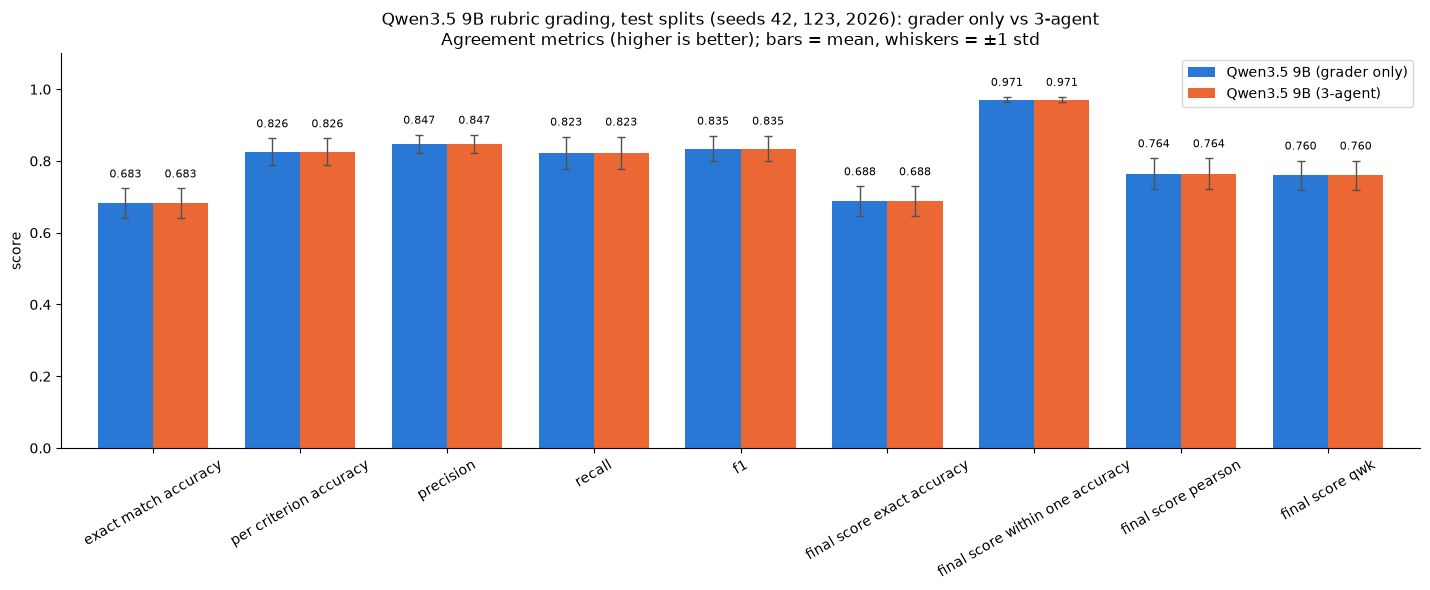

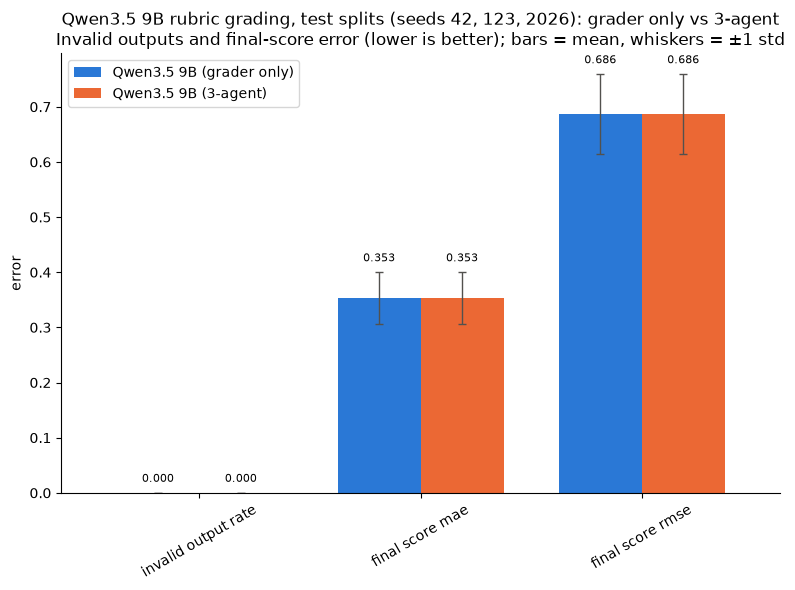

In [35]:
system_names = list(SYSTEMS)

# Metrics x (system, seed / mean / std)
per_seed_table = metrics_by_seed_df.pivot(index="split_seed", columns="model", values=METRIC_COLUMNS)
seed_columns = {}
for name in system_names:
    block = per_seed_table.xs(name, axis=1, level="model").T
    block.columns = [f"Seed {seed}" for seed in block.columns]
    block["Mean"] = block.mean(axis=1)
    block["Std"] = block[[f"Seed {seed}" for seed in TRAINING_SEEDS]].std(axis=1)
    seed_columns[name] = block
per_seed_table_df = pd.concat(seed_columns, axis=1)
per_seed_table_df.to_csv(RESULTS_DIR / f"{RUN_TAG}__per_seed_table.csv", index_label="metric")
display(per_seed_table_df.style.format("{:.4f}"))

means = seed_summary_df.xs("mean", axis=1, level=1).T[system_names]
stds = seed_summary_df.xs("std", axis=1, level=1).T[system_names]
comparison_df = pd.concat({
    **{f"{name} mean": means[name] for name in system_names},
    **{f"{name} std": stds[name] for name in system_names},
}, axis=1)
comparison_df["3-agent minus grader only (mean)"] = means[system_names[1]] - means[system_names[0]]
comparison_df.to_csv(RESULTS_DIR / f"{RUN_TAG}__comparison_metrics.csv", index_label="metric")
display(comparison_df.style.format("{:.4f}"))

SYSTEM_COLORS = ["#2a78d6", "#eb6834"]
accuracy_metrics = [
    "exact_match_accuracy", "per_criterion_accuracy", "precision", "recall", "f1",
    "final_score_exact_accuracy", "final_score_within_one_accuracy",
    "final_score_pearson", "final_score_qwk",
]
error_metrics = ["invalid_output_rate", "final_score_mae", "final_score_rmse"]
seed_label = ", ".join(map(str, TRAINING_SEEDS))

for metrics, title, ylabel, filename in (
    (accuracy_metrics, "Agreement metrics (higher is better)", "score", "accuracy_metrics"),
    (error_metrics, "Invalid outputs and final-score error (lower is better)", "error", "error_metrics"),
):
    chart = means.loc[metrics]
    errors = stds.loc[metrics]
    chart.index = errors.index = [metric.replace("_", " ") for metric in metrics]
    axis = chart.plot(
        kind="bar", yerr=errors, capsize=3, error_kw={"elinewidth": 1, "ecolor": "#52514e"},
        figsize=(max(8, 1.6 * len(metrics)), 6), color=SYSTEM_COLORS, width=0.75,
    )
    for container in axis.containers:
        if hasattr(container, "patches"):
            axis.bar_label(container, fmt="%.3f", fontsize=8, padding=6)
    axis.set_title(
        f"Qwen3.5 9B rubric grading, test splits (seeds {seed_label}): grader only vs 3-agent\n"
        f"{title}; bars = mean, whiskers = ±1 std"
    )
    axis.set_ylabel(ylabel)
    axis.set_xlabel("")
    if ylabel == "score":
        axis.set_ylim(0, 1.1)
    axis.tick_params(axis="x", rotation=30)
    axis.spines[["top", "right"]].set_visible(False)
    axis.legend(title="")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"{RUN_TAG}__{filename}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 13. Inspect agent outputs

This shows rows where the agents disagreed first, followed by other rows, up to 10 in total. Each row shows every agent's criterion marks, the resolution and the feedback.

In [36]:
inspect_columns = [
    "dataset_index", "ground_truth", "grader_prediction", "evaluator_prediction",
    "regrade_prediction", "prediction", "resolution", "true_final_score",
    "predicted_final_score", "feedback_regenerated", "feedback",
]
sample_df = pd.concat([
    records_df[~records_df["agents_agreed"]],
    records_df[records_df["agents_agreed"]],
]).head(10)
with pd.option_context("display.max_colwidth", 400):
    display(sample_df[inspect_columns])

,dataset_index,ground_truth,grader_prediction,evaluator_prediction,regrade_prediction,prediction,resolution,true_final_score,predicted_final_score,feedback_regenerated,feedback
0,83,[1],[1],[1],None,[1],agree,1.0,1,False,"Your answer is correct because it accurately identifies the main function as the entry point for C++ programs. Since this criterion was marked as met, no further improvements are needed for this question."
1,84,[1],[0],[0],None,[0],agree,1.0,0,False,"Your answer was marked not met because you used the term 'main method' instead of the required 'main function', which is the specific terminology expected for C++. To improve, ensure you use the correct term 'function' rather than 'method' when referring to the entry point in C++."
2,85,[1],[1],[1],None,[1],agree,1.0,1,False,"Your answer is correct because you accurately identified that C++ programs begin execution at the main function. Since this criterion was marked as met, no further improvements are needed for this question."
3,86,[1],[1],[1],None,[1],agree,1.0,1,False,"Your answer is correct because you accurately identified that C++ programs begin execution in the main function. Since this criterion was marked as met, no further improvements are needed for this question."
4,87,[1],[1],[1],None,[1],agree,1.0,1,False,"Your answer correctly identified that C++ programs begin execution in the main function, which is why this criterion was marked as met. Since you provided the function signature 'int main()' rather than just the name, your response fully satisfied the requirement."
5,88,[1],[0],[0],None,[0],agree,1.0,0,False,"Your answer was marked not met because the question specifically asks for the 'main function,' whereas you provided 'main method,' which is terminology used in Java rather than C++. To improve, ensure you use the exact term 'main function' as required by the C++ context."
6,89,[0],[0],[0],None,[0],agree,0.0,0,False,"Your answer was marked not met because it did not mention the 'main function,' which is the specific entry point where C++ programs begin execution. To improve, ensure you identify the 'main function' as the starting point rather than referring to the testing phase."
7,90,[1],[1],[1],None,[1],agree,1.0,1,False,"Your answer is correct because you identified 'main' as the starting point, which satisfies the criterion for mentioning the main function. Since this is the only criterion and it is marked as met, you have fully answered the question."
8,91,[1],[1],[1],None,[1],agree,1.0,1,False,"Your answer is correct because you accurately identified that C++ programs begin execution in the main function. Since this criterion was marked as met, no further improvements are needed for this question."
9,92,[1],[0],[0],None,[0],agree,1.0,0,False,"Your answer was marked not met because the question specifically asks for the 'main function,' whereas you provided 'main method,' which is terminology used in Java rather than C++. To improve, ensure you use the correct language-specific term 'function' when answering C++ questions."
